# willmarley: choosing a motor, propeller, and battery

Tracks [issue #85](https://github.com/MarMar888/hav/issues/85).

We have three things to buy. This notebook gives each one its own section — the raw
equations, the inputs it brings, and a low/high range for every input (nothing is
picked yet) — then brings them together into one steady-state answer.

The chain, in words:

> **battery** gives volts and amps → **motor** turns them into torque and rpm →
> **propeller** turns rpm into speed through the water → the **water pushes back** —
> and that push-back is the one input not yet in the solve: section 4 names it,
> section 5 puts an expected size on it.

Every number printed below is computed from the ranges, so edit any bound and re-run.

## 1. The motor

A DC motor is two numbers deep down — `Kv` and `R` — plus two guardrails (`I0`, `I_max`).

```text
Kt  = 60 / (2π · Kv)        torque constant: N·m you get per amp
Q   = Kt · (I − I0)         torque out, for current in (I0 is lost to friction)
rpm = Kv · (V − I · R)      spin rate, for volts in (I·R is lost to the winding)
I  ≤ I_max                  the current guardrail — more amps than this melts it
```

`Kv` is the trade: a high-Kv motor spins faster per volt but makes less torque per
amp. You can't have both — `Kt · Kv` is a constant of nature (60/2π).

input      low     high  unit
Kv         300     1200  rpm/V
R        0.005     0.05  ohm
I0           1        6  A
I_max       50      320  A


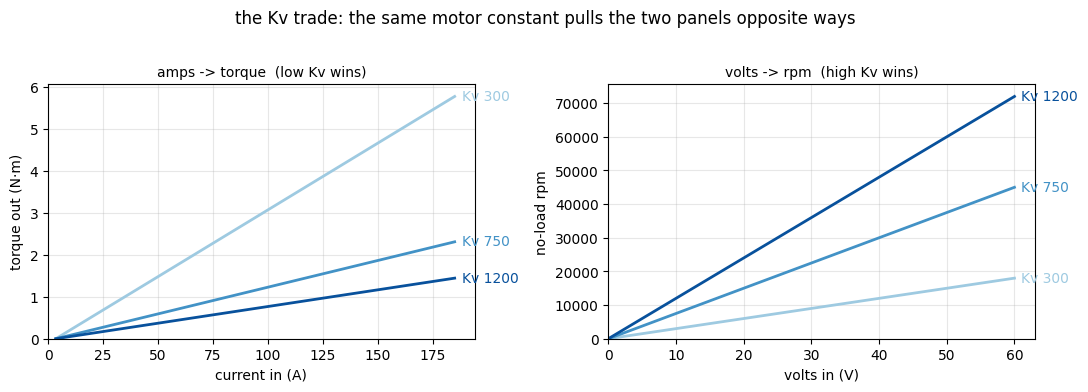

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

RHO = 999.0  # water density, kg/m^3
SEQ = ["#9ecae1", "#4292c6", "#08519c"]  # low / mid / high of one knob, light -> dark

def lo_mid_hi(bounds, key):
    lo, hi = bounds[key]
    return [lo, (lo + hi) / 2, hi]

def show_bounds(bounds, units):
    w = max(len(k) for k in bounds)
    print(f"{'input':<{w}}  {'low':>7}  {'high':>7}  unit")
    for k, (lo, hi) in bounds.items():
        print(f"{k:<{w}}  {lo:>7g}  {hi:>7g}  {units[k]}")

MOTOR_BOUNDS = {
    "Kv":    (300.0, 1200.0),
    "R":     (0.005, 0.050),
    "I0":    (1.0, 6.0),
    "I_max": (50.0, 320.0),
}
MOTOR_UNITS = {"Kv": "rpm/V", "R": "ohm", "I0": "A", "I_max": "A"}
show_bounds(MOTOR_BOUNDS, MOTOR_UNITS)

I0_mid = sum(MOTOR_BOUNDS["I0"]) / 2
Imax_mid = sum(MOTOR_BOUNDS["I_max"]) / 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for Kv, color in zip(lo_mid_hi(MOTOR_BOUNDS, "Kv"), SEQ):
    Kt = 60 / (2 * math.pi * Kv)
    I = np.linspace(I0_mid, Imax_mid, 50)
    ax1.plot(I, Kt * (I - I0_mid), color=color, lw=2)
    ax1.annotate(f"Kv {Kv:g}", (I[-1], Kt * (I[-1] - I0_mid)),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
    V = np.linspace(0, 60, 2)
    ax2.plot(V, Kv * V, color=color, lw=2)
    ax2.annotate(f"Kv {Kv:g}", (V[-1], Kv * V[-1]),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
ax1.set_xlabel("current in (A)"); ax1.set_ylabel("torque out (N·m)")
ax1.set_title("amps -> torque  (low Kv wins)", fontsize=10)
ax2.set_xlabel("volts in (V)"); ax2.set_ylabel("no-load rpm")
ax2.set_title("volts -> rpm  (high Kv wins)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_xlim(left=0); ax.set_ylim(bottom=0)
    ax.margins(x=0.15)
fig.suptitle("the Kv trade: the same motor constant pulls the two panels opposite ways", y=1.02)
plt.tight_layout(); plt.show()

## 2. The propeller

Two raw equations — one for the load it puts on the motor, one for the speed it gives the boat:

```text
Q   = K_Q · ρ · n² · D⁵              torque the water demands to spin it
                                     (n in rev/s, D in meters, ρ = water density)
mph = rpm · pitch · slip / 1056      pitch = inches advanced per rev, like a screw thread
                                     (1056 converts in/min -> mph)
```

What each knob really is:

- **D (diameter)** — the load knob. It enters to the **5th power**, so small diameter
  changes swing the torque demand hugely.
- **pitch** — a pure gear ratio from rpm to speed. (In a real prop it also raises
  `K_Q`; we keep them independent for now.)
- **K_Q** — the blade shape, one constant for a given prop.
- **slip** — the fraction of the pitch you actually get. This is where the water's
  push-back hides (section 4).

input      low     high  unit
K_Q       0.02     0.05  -
D_in         2        5  in
pitch        6       14  in/rev
slip      0.75     0.95  -


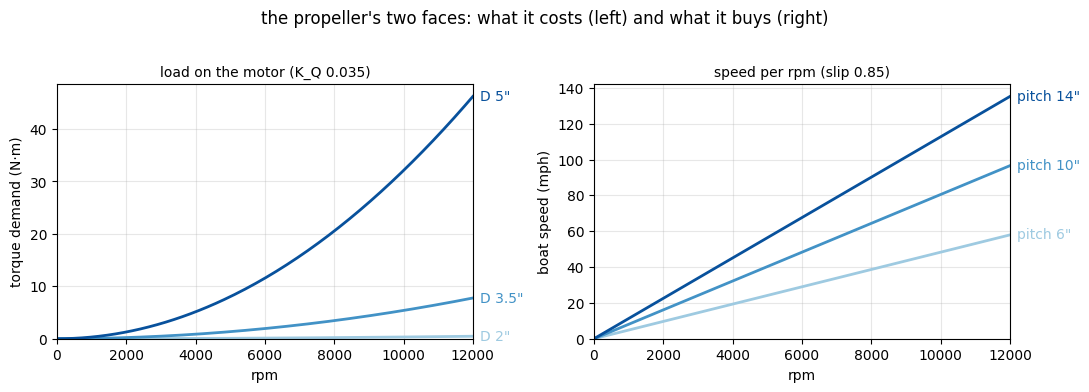

In [2]:
PROP_BOUNDS = {
    "K_Q":   (0.02, 0.05),
    "D_in":  (2.0, 5.0),
    "pitch": (6.0, 14.0),
    "slip":  (0.75, 0.95),
}
PROP_UNITS = {"K_Q": "-", "D_in": "in", "pitch": "in/rev", "slip": "-"}
show_bounds(PROP_BOUNDS, PROP_UNITS)

KQ_mid = sum(PROP_BOUNDS["K_Q"]) / 2
slip_mid = sum(PROP_BOUNDS["slip"]) / 2
rpm = np.linspace(0, 12000, 200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for D_in, color in zip(lo_mid_hi(PROP_BOUNDS, "D_in"), SEQ):
    Q = KQ_mid * RHO * (rpm / 60) ** 2 * (D_in * 0.0254) ** 5
    ax1.plot(rpm, Q, color=color, lw=2)
    ax1.annotate(f'D {D_in:g}"', (rpm[-1], Q[-1]),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
for pitch, color in zip(lo_mid_hi(PROP_BOUNDS, "pitch"), SEQ):
    mph = rpm * pitch * slip_mid / 1056
    ax2.plot(rpm, mph, color=color, lw=2)
    ax2.annotate(f'pitch {pitch:g}"', (rpm[-1], mph[-1]),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
ax1.set_xlabel("rpm"); ax1.set_ylabel("torque demand (N·m)")
ax1.set_title(f"load on the motor (K_Q {KQ_mid:g})", fontsize=10)
ax2.set_xlabel("rpm"); ax2.set_ylabel("boat speed (mph)")
ax2.set_title(f"speed per rpm (slip {slip_mid:g})", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_xlim(0, rpm[-1]); ax.set_ylim(bottom=0)
    ax.margins(x=0.15)
fig.suptitle("the propeller's two faces: what it costs (left) and what it buys (right)", y=1.02)
plt.tight_layout(); plt.show()

## 3. The battery

The battery brings three numbers: volts, amp-hours, and how much of them you can actually use.

```text
P_elec  = V · I                  watts drawn from the pack
minutes = 60 · usable · C / I    runtime at a steady current draw
```

Volts set the motor's rpm headroom. Amp-hours set the minutes. (A real pack also has a
discharge-current limit — for now the motor's `I_max` plays that role for both.)

input       low     high  unit
V            20       50  V
C            40      200  Ah
usable      0.7      0.9  -


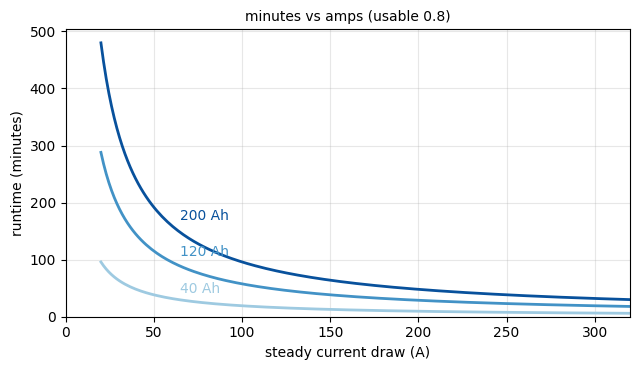

In [3]:
BATT_BOUNDS = {
    "V":      (20.0, 50.0),
    "C":      (40.0, 200.0),
    "usable": (0.7, 0.9),
}
BATT_UNITS = {"V": "V", "C": "Ah", "usable": "-"}
show_bounds(BATT_BOUNDS, BATT_UNITS)

usable_mid = sum(BATT_BOUNDS["usable"]) / 2
I = np.linspace(20, 320, 200)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for C, color in zip(lo_mid_hi(BATT_BOUNDS, "C"), SEQ):
    minutes = 60 * usable_mid * C / I
    ax.plot(I, minutes, color=color, lw=2)
    x_lab = 60.0  # label where the curves are still well separated
    ax.annotate(f"{C:g} Ah", (x_lab, 60 * usable_mid * C / x_lab),
                xytext=(6, 4), textcoords="offset points", color=color)
ax.set_xlabel("steady current draw (A)"); ax.set_ylabel("runtime (minutes)")
ax.set_title(f"minutes vs amps (usable {usable_mid:g})", fontsize=10)
ax.grid(alpha=0.3); ax.set_xlim(0, I[-1]); ax.set_ylim(bottom=0)
ax.margins(x=0.15)
plt.tight_layout(); plt.show()

## 4. The water (still undefined)

The one input we do **not** have: the hull's resistance while planing — the force the
water pushes back with at speed. Call it `R_water`. The propeller's thrust has to cover it:

```text
T = K_T · ρ · n² · D⁴        thrust the prop makes (same family as the torque equation)
T ≥ R_water(speed)           planing condition     <- R_water is UNDEFINED
```

Until we measure or estimate `R_water`, the model stands in for it with the **slip
range** from section 2: a hull that pushes back harder is a prop that slips more.
Once `R_water` is defined, slip stops being a guess and gets *solved* from
thrust = resistance.

In [4]:
R_WATER_LBF = None  # hull resistance on plane, lbf -- fill in when known

if R_WATER_LBF is None:
    lo, hi = PROP_BOUNDS["slip"]
    print("R_water: UNDEFINED")
    print(f"stand-in: slip in [{lo:g}, {hi:g}] (section 2) absorbs whatever the water does")
else:
    print(f"R_water = {R_WATER_LBF:g} lbf -> next step: solve slip from thrust = resistance")

R_water: UNDEFINED
stand-in: slip in [0.75, 0.95] (section 2) absorbs whatever the water does


## 5. How big should R_water be?

Before running the model, put an expected size on the missing input. On plane, a hull's
resistance is just its weight divided by how efficiently it rides — its lift-to-drag ratio:

```text
R_water ≈ W / (L/D)
```

A hull that planes pretty well holds **L/D ≈ 5–6** just after it gets on plane. Push it
faster and skin friction (which grows with speed²) drags L/D down — toward **~2.5** when
it's being driven hard. (Cross-checked against the Savitsky planing model in
`explore.ipynb`'s library across several small-hull shapes; the numbers land in the same band.)

The second thing worth knowing is what that resistance *costs*: towing power is
`P = R_water × speed`, and that's the bill the motor eventually has to pay — it is the
physics the slip stand-in currently papers over.

expected resistance for a 130 lb boat on plane:
  just on plane      (L/D 6.5)   ~  20 lbf
  planes pretty well (L/D 5)     ~  26 lbf   <- starting number
  driven hard        (L/D 2.5)   ~  52 lbf


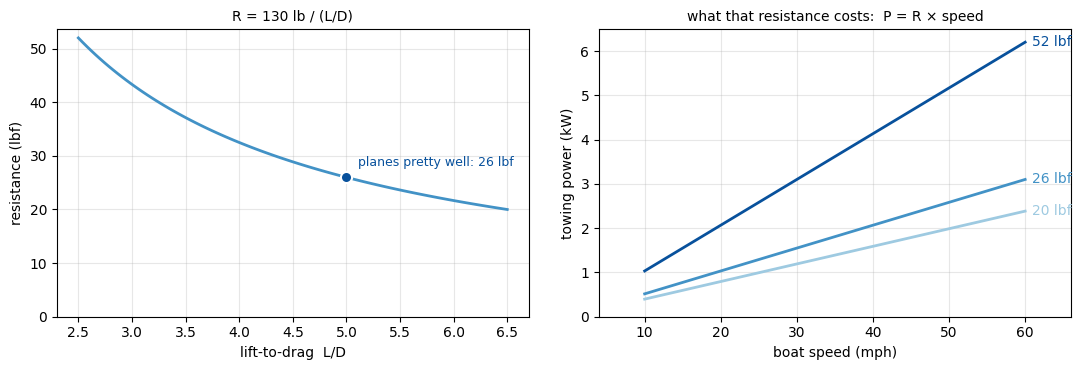

In [5]:
W_LB = 130.0              # the boat, all-up, in the water, lb
LD_ON_PLANE = (2.5, 6.5)  # lift-to-drag: driven hard ... just on plane
LD_TYPICAL = 5.0          # "planes pretty well"

R_expect = (W_LB / LD_ON_PLANE[1], W_LB / LD_ON_PLANE[0])  # lbf, low..high
R_typ = W_LB / LD_TYPICAL
print(f"expected resistance for a {W_LB:g} lb boat on plane:")
print(f"  just on plane      (L/D {LD_ON_PLANE[1]:g})   ~{R_expect[0]:4.0f} lbf")
print(f"  planes pretty well (L/D {LD_TYPICAL:g})     ~{R_typ:4.0f} lbf   <- starting number")
print(f"  driven hard        (L/D {LD_ON_PLANE[0]:g})   ~{R_expect[1]:4.0f} lbf")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
LD = np.linspace(*LD_ON_PLANE, 100)
ax1.plot(LD, W_LB / LD, color="#4292c6", lw=2)
ax1.plot(LD_TYPICAL, R_typ, "o", color="#08519c", ms=8,
         markeredgecolor="white", markeredgewidth=1.5, zorder=5)
ax1.annotate(f"planes pretty well: {R_typ:.0f} lbf", (LD_TYPICAL, R_typ),
             xytext=(8, 8), textcoords="offset points", color="#08519c", fontsize=9)
ax1.set_xlabel("lift-to-drag  L/D"); ax1.set_ylabel("resistance (lbf)")
ax1.set_title(f"R = {W_LB:g} lb / (L/D)", fontsize=10)
v = np.linspace(10, 60, 100)
for R, color in zip((R_expect[0], R_typ, R_expect[1]), SEQ):
    P_kw = R * 4.4482 * v * 0.44704 / 1000
    ax2.plot(v, P_kw, color=color, lw=2)
    ax2.annotate(f"{R:.0f} lbf", (v[-1], P_kw[-1]),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
ax2.set_xlabel("boat speed (mph)"); ax2.set_ylabel("towing power (kW)")
ax2.set_title("what that resistance costs:  P = R × speed", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_ylim(bottom=0)
ax2.margins(x=0.12)
plt.tight_layout(); plt.show()

## 6. Bring it together

Steady state is one sentence: **the torque the motor makes equals the torque the
propeller demands, at the same rpm.** Substituting the motor equations into the
propeller equation gives a quadratic in rpm:

```text
a · rpm² + b · rpm = c            where   a = K_Q · ρ · D⁵ / 3600
                                          b = Kt / (Kv · R)
rpm = (−b + √(b² + 4·a·c)) / 2a           c = Kt · (V / R − I0)
```

One check after solving: if the implied current exceeds `I_max`, the motor pins at its
guardrail instead — torque locks to `Kt·(I_max − I0)` and the rpm comes from the
propeller equation alone. Then pitch turns rpm into mph, and the battery turns amps
into minutes.

In [6]:
BOUNDS = {**MOTOR_BOUNDS, **PROP_BOUNDS, **BATT_BOUNDS}
MID = {k: (lo + hi) / 2 for k, (lo, hi) in BOUNDS.items()}

def steady_state(Kv, R, I0, I_max, V, K_Q, D_in, pitch, slip, C, usable):
    Kt = 60 / (2 * math.pi * Kv)
    a = K_Q * RHO * (D_in * 0.0254) ** 5 / 3600
    b = Kt / (Kv * R)
    c = Kt * (V / R - I0)
    rpm = (-b + math.sqrt(b * b + 4 * a * c)) / (2 * a)
    I = (V - rpm / Kv) / R
    limited = I > I_max
    if limited:
        I = I_max
        torque = Kt * (I_max - I0)
        rpm = 60 * math.sqrt(torque / (K_Q * RHO * (D_in * 0.0254) ** 5))
    else:
        torque = Kt * (I - I0)
    speed = rpm * pitch * slip / 1056
    shaft_w = torque * 2 * math.pi * rpm / 60
    return dict(rpm=rpm, torque=torque, I=I, limited=limited, speed=speed,
                shaft_w=shaft_w, elec_w=V * I, eff=shaft_w / (V * I),
                minutes=60 * usable * C / I)

def solve(**over):
    return steady_state(**{**MID, **over})

mid = solve()
print("everything at the middle of its range:")
print(f"  rpm         {mid['rpm']:8.0f}" + ("   (current-limited)" if mid['limited'] else ""))
print(f"  torque      {mid['torque']:8.2f}  N·m")
print(f"  current     {mid['I']:8.0f}  A")
print(f"  speed       {mid['speed']:8.1f}  mph")
print(f"  shaft power {mid['shaft_w']:8.0f}  W")
print(f"  elec power  {mid['elec_w']:8.0f}  W   (efficiency {mid['eff']:.2f})")
print(f"  runtime     {mid['minutes']:8.1f}  min")

# reality check against section 5: can the shaft power actually tow the hull that fast?
v_ms = mid["speed"] * 0.44704
tow_kw = tuple(R * 4.4482 * v_ms / 1000 for R in R_expect)
shaft_kw = mid["shaft_w"] / 1000
if shaft_kw < tow_kw[0]:
    verdict = "the mph above is optimistic: not enough shaft power to tow the hull that fast"
elif shaft_kw > tow_kw[1]:
    verdict = "the mph above is conservative: shaft power to spare"
else:
    verdict = "shaft power and towing power are in the same band"
print()
print(f"reality check (section 5): towing {W_LB:g} lb at {mid['speed']:.1f} mph takes "
      f"~{tow_kw[0]:.1f}-{tow_kw[1]:.1f} kW before prop losses,")
print(f"  and the motor delivers {shaft_kw:.1f} kW at the shaft -> {verdict}")
print("  (the solve still rides on the slip range; feeding R_water in is the next step)")

everything at the middle of its range:
  rpm             6546   (current-limited)
  torque          2.31  N·m
  current          185  A
  speed           52.7  mph
  shaft power     1584  W
  elec power      6475  W   (efficiency 0.24)
  runtime         31.1  min

reality check (section 5): towing 130 lb at 52.7 mph takes ~2.1-5.4 kW before prop losses,
  and the motor delivers 1.6 kW at the shaft -> the mph above is optimistic: not enough shaft power to tow the hull that fast
  (the solve still rides on the slip range; feeding R_water in is the next step)


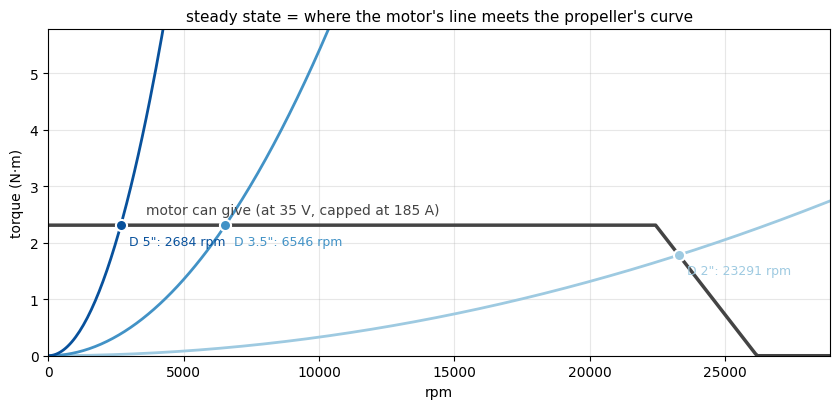

In [7]:
# the mechanism in one picture: motor's available torque vs the propeller's demand
Kv, R, I0, I_max, V = (MID[k] for k in ("Kv", "R", "I0", "I_max", "V"))
Kt = 60 / (2 * math.pi * Kv)
rpm_free = Kv * V
rpm_axis = np.linspace(1, 1.1 * rpm_free, 400)
I_avail = np.clip((V - rpm_axis / Kv) / R, 0, I_max)
Q_motor = np.maximum(Kt * (I_avail - I0), 0)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(rpm_axis, Q_motor, color="#444444", lw=2.5)
ax.annotate(f"motor can give (at {V:g} V, capped at {I_max:g} A)",
            (rpm_axis[len(rpm_axis) // 8], Kt * (I_max - I0)),
            xytext=(0, 8), textcoords="offset points", color="#444444")
for D_in, color in zip(lo_mid_hi(PROP_BOUNDS, "D_in"), SEQ):
    Q_prop = MID["K_Q"] * RHO * (rpm_axis / 60) ** 2 * (D_in * 0.0254) ** 5
    ax.plot(rpm_axis, Q_prop, color=color, lw=2)
    op = solve(D_in=D_in)
    ax.plot(op["rpm"], op["torque"], "o", color=color, ms=8,
            markeredgecolor="white", markeredgewidth=1.5, zorder=5)
    ax.annotate(f'D {D_in:g}": {op["rpm"]:.0f} rpm', (op["rpm"], op["torque"]),
                xytext=(6, -14), textcoords="offset points", color=color, fontsize=9)
ax.set_xlabel("rpm"); ax.set_ylabel("torque (N·m)")
ax.set_title("steady state = where the motor's line meets the propeller's curve", fontsize=11)
ax.set_xlim(0, rpm_axis[-1]); ax.set_ylim(0, 2.5 * Kt * (I_max - I0))
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

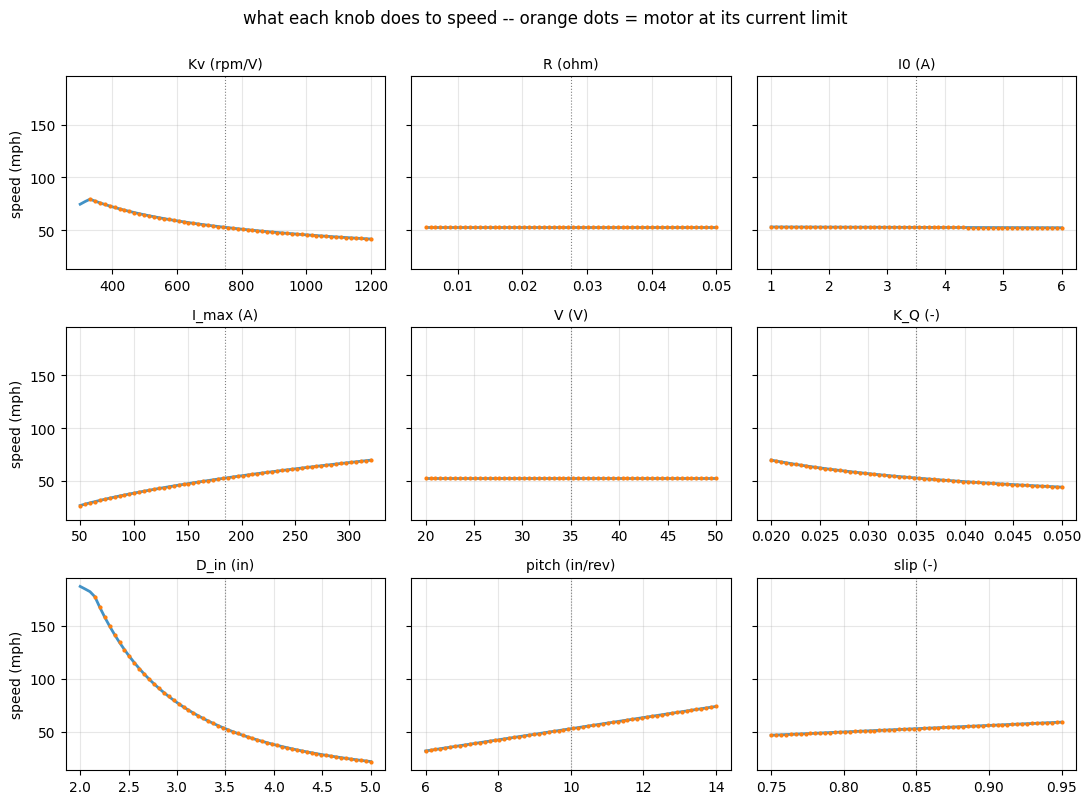

In [8]:
# one panel per input: sweep it across its range, everything else at mid
SWEEP = ["Kv", "R", "I0", "I_max", "V", "K_Q", "D_in", "pitch", "slip"]
UNITS = {**MOTOR_UNITS, **PROP_UNITS, **BATT_UNITS}
fig, axes = plt.subplots(3, 3, figsize=(11, 8), sharey=True)
for key, ax in zip(SWEEP, axes.flat):
    lo, hi = BOUNDS[key]
    xs = np.linspace(lo, hi, 60)
    res = [solve(**{key: x}) for x in xs]
    ys = [r["speed"] for r in res]
    lim = np.array([r["limited"] for r in res])
    ax.plot(xs, ys, color="#4292c6", lw=2)
    if lim.any():
        ax.plot(xs[lim], np.array(ys)[lim], ".", color="tab:orange", ms=4)
    ax.axvline(MID[key], color="gray", lw=0.8, ls=":")
    ax.set_title(f"{key} ({UNITS[key]})", fontsize=10)
    ax.grid(alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel("speed (mph)")
fig.suptitle("what each knob does to speed -- orange dots = motor at its current limit", y=1.0)
plt.tight_layout(); plt.show()

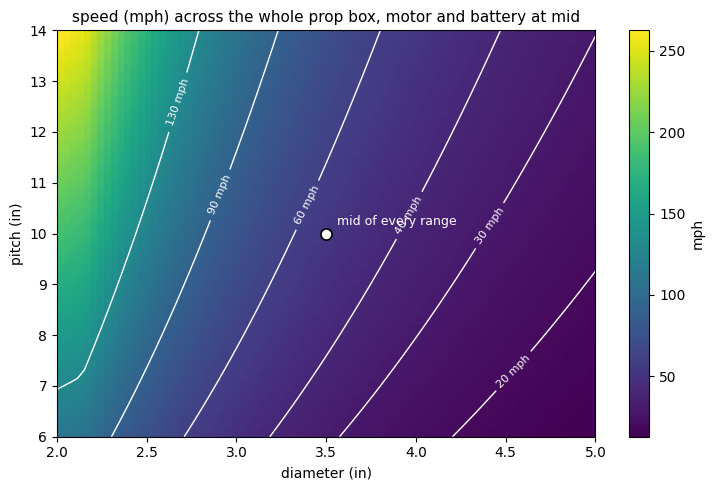

caution, top-left corner: 262 mph at 23291 rpm -- pitch here is a free gear ratio; a real prop's K_Q rises with pitch and would pull this down


In [9]:
# the two numbers printed on a propeller, mapped to the speed they produce
D_axis = np.linspace(*PROP_BOUNDS["D_in"], 80)
P_axis = np.linspace(*PROP_BOUNDS["pitch"], 80)
speed = np.array([[solve(D_in=D, pitch=p)["speed"] for D in D_axis] for p in P_axis])

fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(speed, origin="lower", aspect="auto", cmap="viridis",
               extent=[D_axis[0], D_axis[-1], P_axis[0], P_axis[-1]])
levels = [lv for lv in (20, 30, 40, 60, 90, 130) if speed.min() < lv < speed.max()]
cs = ax.contour(D_axis, P_axis, speed, levels=levels, colors="white", linewidths=1)
ax.clabel(cs, fmt="%g mph", fontsize=8)
ax.plot(MID["D_in"], MID["pitch"], "o", color="white", ms=8,
        markeredgecolor="black", markeredgewidth=1.2)
ax.annotate("mid of every range", (MID["D_in"], MID["pitch"]),
            xytext=(8, 6), textcoords="offset points", color="white", fontsize=9)
ax.set_xlabel("diameter (in)"); ax.set_ylabel("pitch (in)")
ax.set_title("speed (mph) across the whole prop box, motor and battery at mid", fontsize=11)
fig.colorbar(im, ax=ax, label="mph")
plt.tight_layout(); plt.show()

corner = solve(D_in=D_axis[0], pitch=P_axis[-1])
print(f"caution, top-left corner: {corner['speed']:.0f} mph at {corner['rpm']:.0f} rpm -- "
      "pitch here is a free gear ratio; a real prop's K_Q rises with pitch and would pull this down")

## What's deliberately missing

Each of these is one line to add, once we want it:

1. **`R_water` into the solve** — section 5 already sizes it; the step left is feeding it
   in, so slip gets *solved* from thrust = resistance instead of guessed as a range.
2. **Couple `K_Q` to pitch** — real props demand more torque as pitch rises (roughly
   `K_Q ∝ pitch / D`), which turns pitch's free speed into a √pitch gain.
3. **Battery discharge limit** — a pack `I_max` alongside the motor's; the smaller
   one wins.